# **Sesión 4:** Procesamiento de imagenes y extracción de características

## **Librerías**

In [24]:
import cv2
import os

## **Apartado A:** Detección de lineas rectas
El objetivo de este apartado es la detección de líneas y bordes en las imágenes de la carpeta `data/partA`.
1. **Tarea A.1.** Aplique `cv2.Canny()` a las imágenes de trabajo ajustando los hiperparámetros.
3. **Tarea A.2.** Implemente la función `draw_lines()` para pintar las líneas sobre las imágenes.
4. **Tarea A.3.** Aplique Hough con `cv2.HoughLinesP()` a las imágenes de trabajo para extraer líneas y afine los hiperparámetros.
5. **Problema A.1.** Repita el procedimiento para extraer las líneas de las dos imágenes restantes.

### **NOTA**
Podéis usar el mismo formato de guardado de resultados y nomenclatura que en en las práctica 3 o hacer uso de la funcion `show_image()` del Lab 1. Usad las herramientas con las que os sintáis más cómodos

In [25]:
# Nos definimos estas funciones auxiliares que nos facilitará algunas tareas más adelante

from rpds import List
import numpy as np

def show_image(img: np.array, img_name: str = "Image"):
    cv2.imshow(img_name, img)  # Mostramos la imagen, poniendole el nombre correspondiente a la ventana desplegada
    cv2.waitKey(0)  # Ponemos una tecla para eliminar la ventana y pasar a la siguiente imagen o terminar la visualización
    cv2.destroyAllWindows()

def load_images(filenames: List) -> List:
    return [cv2.imread(filename) for filename in filenames]

def write_image(output_folder: str, img_name: str, img: np.array):
    img_path = os.path.join(output_folder, img_name)  # creamos el path donde vamos a guardar la imagen
    os.makedirs(output_folder, exist_ok=True)
    cv2.imwrite(img_path, img)  # guardamos la imagen en su correspondiente ubicación

In [26]:
# Cargamos las imágenes correspondientes al apartado A de la práctica

import glob

imgs_gen_path = '../data/partA/*' # Patrón que cumplen todos los paths de los archivos de imágenes de la carpeta data/partA
imgs_path = sorted(glob.glob(imgs_gen_path))  # Cogemos todos los paths que cumplen ese patrón genérico (usando glob) y los ordenamos (usando sorted)
imgs = load_images(imgs_path)  # Le pasamos a load_images la lista de paths o filenames de las imágenes que queremos cargar

imgs_path


['../data/partA\\0.jpg',
 '../data/partA\\1.png',
 '../data/partA\\2.png',
 '../data/partA\\3.png']

### **Tarea A.1.** Aplique `cv2.Canny()` a las imágenes de trabajo ajustando los hiperparámetros

In [27]:
# TODO Apply canny to the images, play with the thresholds to get a good result

edge_imgs = []  # to store the canny edge images for later Hough transform

# 1st image

# Hyperparameters
low_threshold = 50
high_threshold = 100

# get the first image
img = imgs[0]

# Convert to grayscale
gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Apply Canny edge detection
edge_img = cv2.Canny(gray_img, low_threshold, high_threshold)

# Store the edge image for later Hough transform
edge_imgs.append(edge_img)

# Display the image or save it as you like
show_image(edge_img, "Canny Edge Image 1")

# 2nd image
img = imgs[1]

# Convert to grayscale
gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Apply Canny edge detection
edge_img = cv2.Canny(gray_img, low_threshold, high_threshold)

# Store the edge image for later Hough transform
edge_imgs.append(edge_img)

# Display the image or save it as you like
show_image(edge_img, "Canny Edge Image 2")

for img in imgs[2:]:
    # Convert to grayscale
    gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Apply Canny edge detection
    edge_img = cv2.Canny(gray_img, low_threshold, high_threshold)

    # Store the edge image for later Hough transform
    edge_imgs.append(edge_img)

### **Tarea A.2.** Implemente `draw_lines()` para pintar las lineas sobre cada imagen

In [28]:
# TODO Draw the lines on the images. A line is a tuple of 4 integers (x1, y1, x2, y2) where (x1, y1) and (x2, y2) are the coordinates of the two points of the line.
def draw_lines(img, lines, color, thickness):
    # Iteramos por cada una de las líneas detectadas
    for line in lines:
        # Extraemos las coordenadas x,y de los 2 puntos que definen la línea
        x1, y1, x2, y2 = line[0]
        # Pintamos la línea sobre la imnagen, sobreescribiéndola
        cv2.line(img, (x1, y1), (x2, y2), color, thickness)

### **Tarea A.3.** Aplique Hough con `cv2.HoughLinesP()` a las imágenes de trabajo para extraer líneas y afine los hiperparámetros

In [29]:
# TODO Apply the hough transform to the images, play with the parameters to get a good result

# Hacemos una copia de las imágenes originales ya que al pintar sobre ellas las estaremos sobreescribiendo
new_imgs = imgs.copy()  

In [30]:
# 1st image

# Define the hough transform parameters: Estos parámetros los hemos elegido tras hacer múltiples pruebas y conseguir afinarlos bien
rho = 1
theta = np.pi/180
threshold = 45
min_line_length = 1
max_line_gap = 5

# Get the edge image
edges1 = edge_imgs[0]

# Apply the hough transform
lines = cv2.HoughLinesP(edges1, rho, theta, threshold, minLineLength=min_line_length, maxLineGap=max_line_gap)

# Draw the lines on the image (on the original image, make sure to get a copy, as draw_lines modifies the image)
draw_lines(new_imgs[0], lines, (0, 255, 0), 2)

# Show the image or save it as you like
show_image(new_imgs[0], "Hough Lines Image 1")


In [31]:
# 2nd image

# Estos parámetros los hemos elegido tras hacer múltiples pruebas y conseguir afinarlos bien
rho = 1
theta = np.pi/180
threshold = 45
min_line_length = 10
max_line_gap = 5

# Get the edge image
edges2 = edge_imgs[1]

# Apply the hough transform
lines = cv2.HoughLinesP(edges2, rho, theta, threshold, minLineLength=min_line_length, maxLineGap=max_line_gap)

# Draw the lines on the image (on the original image, make sure to get a copy, as draw_lines modifies the image)
draw_lines(new_imgs[1], lines, (0, 255, 0), 2)

# Show the image or save it as you like
show_image(new_imgs[1], "Hough Lines Image 2")

### **Problema A.1.** Repita el procedimiento para extraer las líneas de las dos imágenes restantes

In [32]:
# TODO Homework

# 3rd image

# Estos parámetros los hemos elegido tras hacer múltiples pruebas y conseguir afinarlos bien
rho = 1
theta = np.pi/180
threshold = 45
min_line_length = 0.01
max_line_gap = 10

# Get the edge image
edges2 = edge_imgs[2]

# Apply the hough transform
lines = cv2.HoughLinesP(edges2, rho, theta, threshold, minLineLength=min_line_length, maxLineGap=max_line_gap)

# Draw the lines on the image (on the original image, make sure to get a copy, as draw_lines modifies the image)
draw_lines(new_imgs[2], lines, (0, 255, 0), 2)

# Show the image or save it as you like
show_image(new_imgs[2], "Hough Lines Image 3")



In [33]:
# 4th image

# Estos parámetros los hemos elegido tras hacer múltiples pruebas y conseguir afinarlos bien
rho = 1
theta = np.pi/180
threshold = 45
min_line_length = 10
max_line_gap = 10

# Get the edge image
edges3 = edge_imgs[3]

# Apply the hough transform
lines = cv2.HoughLinesP(edges3, rho, theta, threshold, minLineLength=min_line_length, maxLineGap=max_line_gap)

# Draw the lines on the image (on the original image, make sure to get a copy, as draw_lines modifies the image)
draw_lines(new_imgs[3], lines, (0, 255, 0), 2)

# Show the image or save it as you like
show_image(new_imgs[3], "Hough Lines Image 4")

# Barrido de parametros para observar distintas combinaciones y analizar resultados:

In [39]:
# Queda un poco meh la comparación, quizá no aporta demasiado y no hace falta ponerla. # TODO

In [34]:
# import cv2
# import numpy as np
import itertools
import matplotlib.pyplot as plt

def show_hough_param_grid(img_bgr, edges, param_grid, n_cols=3):
    """
    Muestra un grid de subplots con el resultado de HoughLinesP
    para cada combinación de parámetros en param_grid.
    
    img_bgr: imagen original en BGR
    edges: imagen de bordes (por ejemplo, Canny)
    param_grid: lista de tuplas (rho, theta, threshold, minLineLength, maxLineGap)
    n_cols: número de columnas en el grid de subplots
    """
    n = len(param_grid)
    n_rows = int(np.ceil(n / n_cols))
    
    plt.figure(figsize=(4 * n_cols, 4 * n_rows))
    
    for idx, (rho, theta, thr, min_len, max_gap) in enumerate(param_grid):
        # Detección de líneas
        lines = cv2.HoughLinesP(
            edges,
            rho=rho,
            theta=theta,
            threshold=thr,
            minLineLength=min_len,
            maxLineGap=max_gap
        )
        
        # Copia de la imagen original para dibujar
        vis = img_bgr.copy()
        if lines is not None:
            for x1, y1, x2, y2 in lines.reshape(-1, 4):
                cv2.line(vis, (x1, y1), (x2, y2), (0, 0, 255), 2)
        
        plt.subplot(n_rows, n_cols, idx + 1)
        plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
        plt.axis("off")
        
        theta_deg = int(np.round(theta * 180 / np.pi))
        plt.title(
            f"ρ={rho}, θ={theta_deg}°\nT={thr}, Lmin={min_len}, Gap={max_gap}",
            fontsize=8
        )
    
    plt.tight_layout()
    plt.show()


In [35]:
# Rangos de parámetros
rhos = [1, 2]
thetas = [np.pi/180, np.pi/90]      # 1º y 2º
thresholds = [50, 100]              # votos mínimos
min_line_lengths = [50, 150]        # longitud mínima
max_line_gaps = [10]                # gap máximo (lo dejamos fijo aquí)

# Crear lista de combinaciones (rho, theta, threshold, minLineLength, maxLineGap)
param_grid = list(itertools.product(
    rhos, thetas, thresholds, min_line_lengths, max_line_gaps
))

print(f"Número de combinaciones: {len(param_grid)}")


Número de combinaciones: 16


In [37]:
new_imgs2 = imgs.copy()  

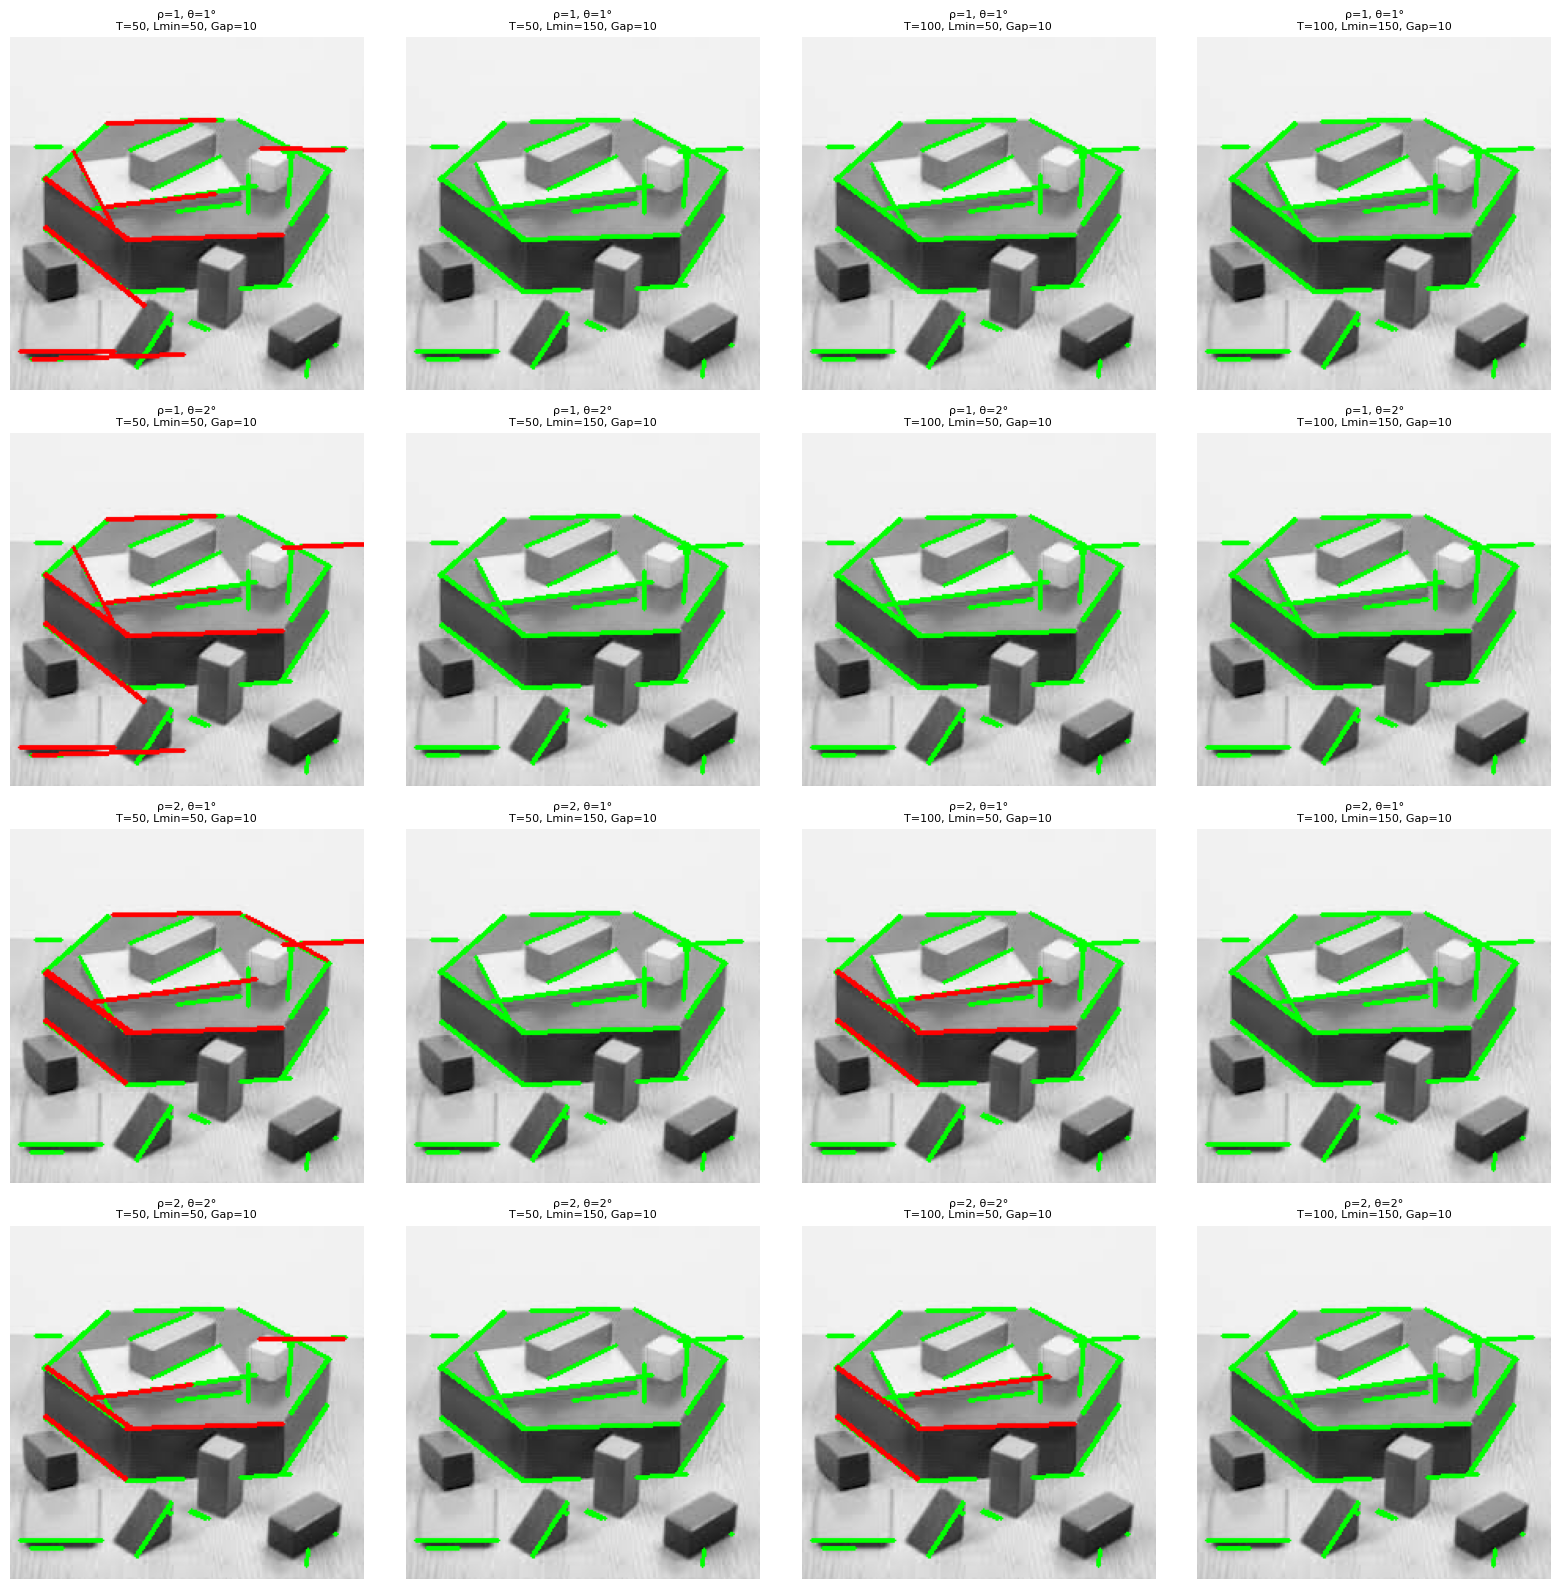

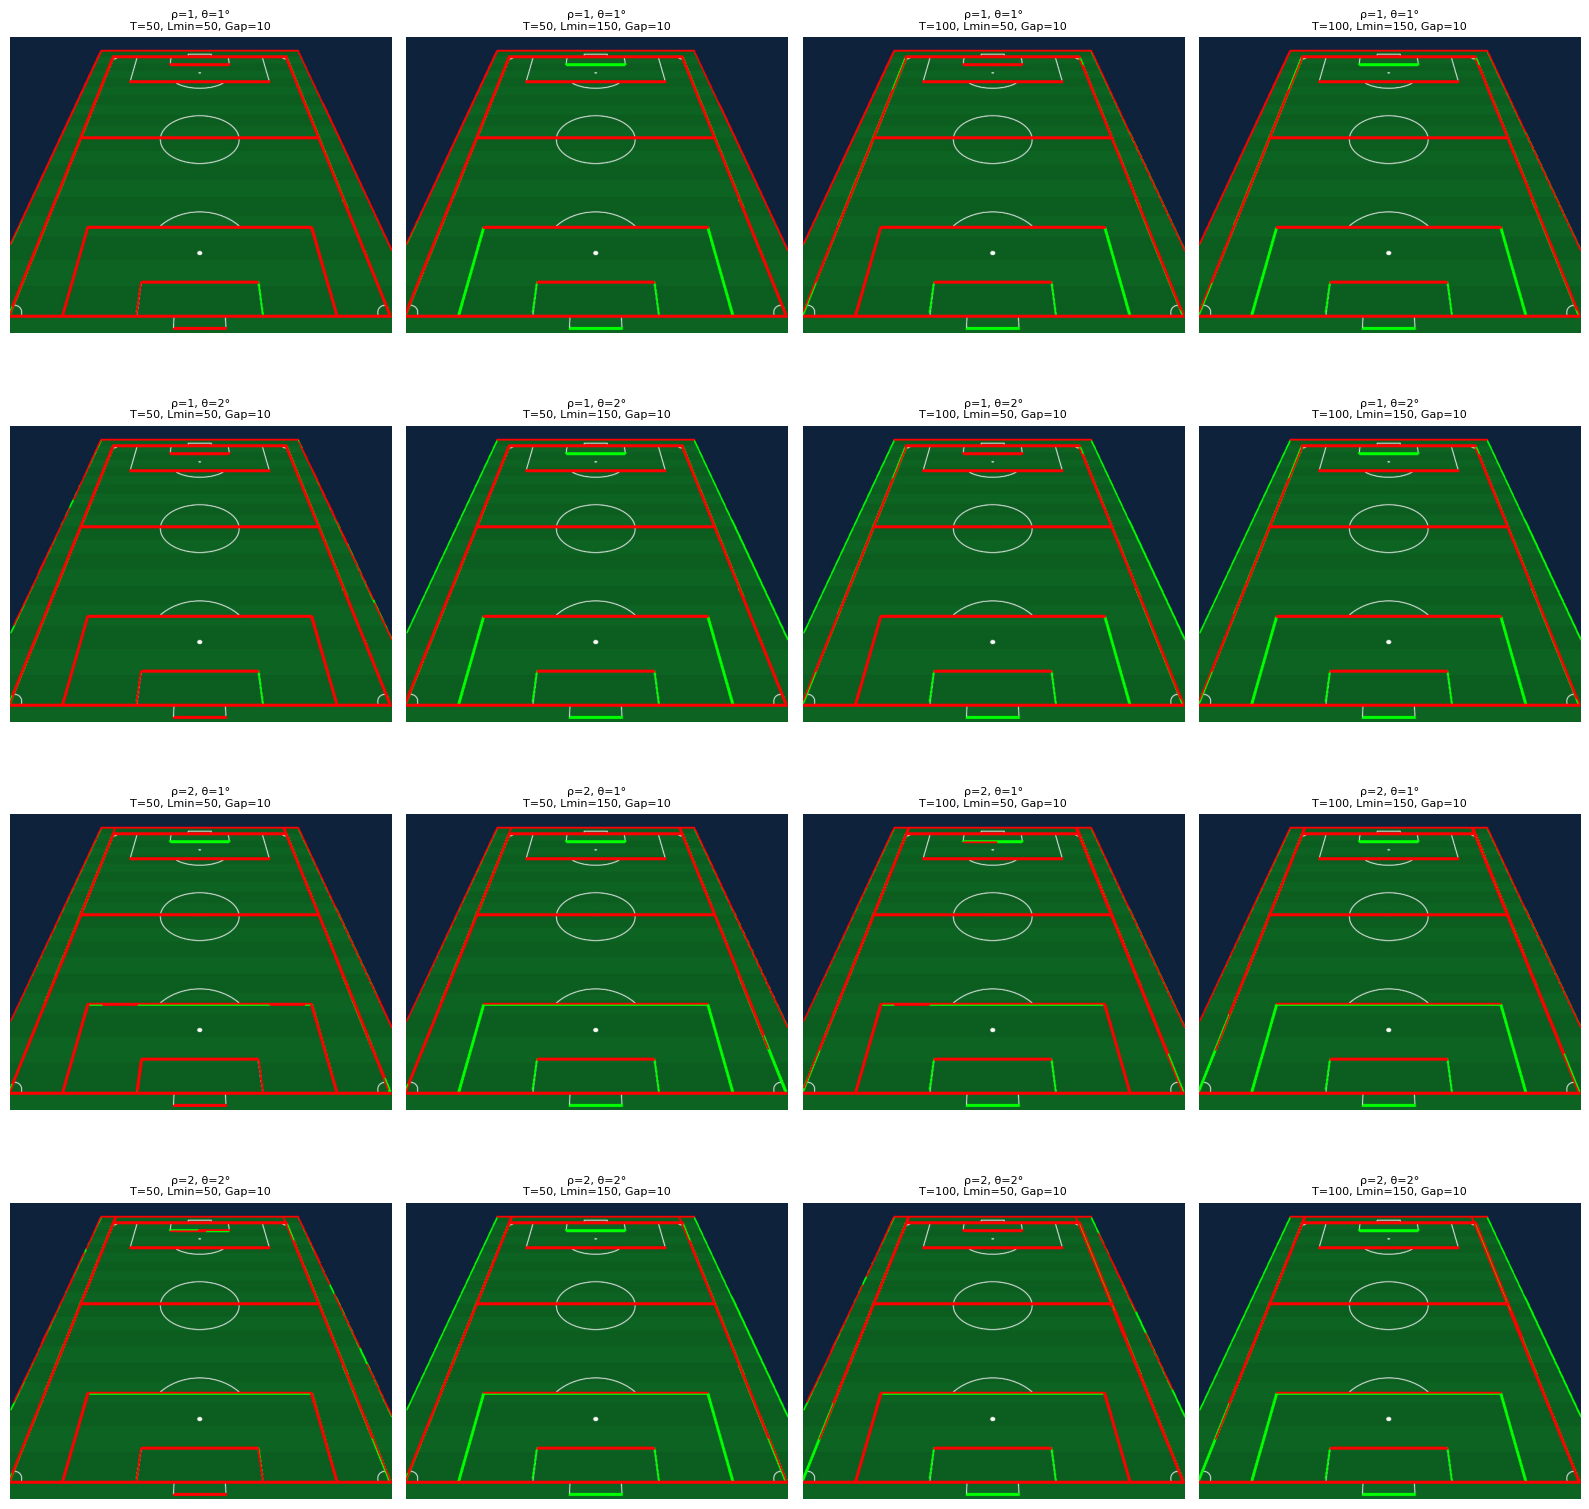

In [38]:
# Imagen 3
show_hough_param_grid(
    img_bgr=new_imgs2[0],       # original
    edges=edge_imgs[0],    # bordes (Canny)
    param_grid=param_grid,
    n_cols=4               # 4 columnas para 16 combinaciones
)

# Imagen 4
show_hough_param_grid(
    img_bgr=new_imgs2[1],
    edges=edge_imgs[1],
    param_grid=param_grid,
    n_cols=4
)
